# V34: cheap reward residual failed the information gate

One published nonnegative scalar reward offset was tested with nested grouped
validation on all1,024complete cached source pairs. Tie mass stayed fixed.
Baseline loss0.997842became0.998783; paired gain−0.000941with95% interval
[−0.002154,+0.000203] fails the required0.001gain/positive lower bound.
There is no GPU follow-up, final deployment coefficient or official submission.

The source is historically inspected; reward pretraining exposure is unknown.
Old v16serviceERROR and missing reverse-H60 outputs remain explicit. This
compares complete two-expert caches, not currentH60or independent target CV.
Method/input publication27e2165preceded label access. No model-size/family search.

[Protocol](../docs/SPAN_034_PLAN.md) · [Results](../docs/SPAN_034_RESULTS.md).
The persistent goal remains actual rank19or better.

,model,log_loss,accuracy,macro_f1,brier
0,baseline,0.997842,0.495117,0.480584,0.595285
1,candidate,0.998783,0.493164,0.478424,0.595684
2,prior,1.095035,0.370117,0.180090,0.664331
3,hard_majority,17.404305,0.370117,0.180090,1.259766


Prior/hard-majority baselines fit only outer-training labels; hard log-loss floor1e-12.
Paired prompt-group gain: {'gain': -0.000940814059358272, 'interval_95': [-0.0021544925235044625, 0.00020297673611336986], 'groups': 1024, 'rows': 1024, 'replicates': 2000}
Decision: stop_no_qualified_reward_residual_gain ; useful information: False


,fold,alpha,scale,penalty,fit_rows,non_tie_rows
0,0,0.000000,3.089812,1.00,807,573
1,1,0.000000,3.167035,1.00,827,584
2,2,0.016847,3.192143,1.00,816,579
3,3,0.042691,3.207572,0.01,810,570
4,4,0.098801,3.163455,0.10,836,594


,model,label,loss,recall
0,baseline,A,0.998230,0.535620
1,baseline,B,0.901856,0.609827
2,baseline,tie,1.108425,0.311037
3,candidate,A,0.999614,0.538259
4,candidate,B,0.903124,0.604046
5,candidate,tie,1.108425,0.307692


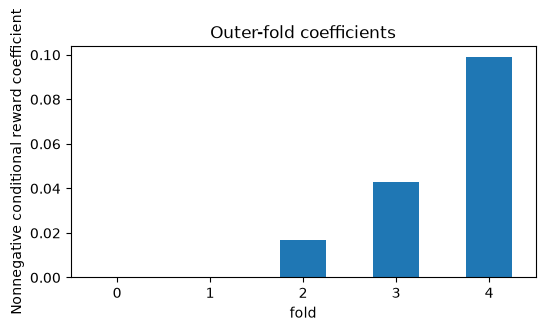

Tie channel/zero correction/bitwise swap: True True True
Tie probability retention does not fix tie argmax recall when A/B probabilities change.
Analysis seconds/RSS GiB: 0.4184351689182222 0.9912452697753906
resource_close.json {'at': '2026-11-09T09:08:18.290362+00:00', 'passed': True, 'quota': {'used_seconds': 36651.064, 'reserved_seconds': 0.0, 'allowed_seconds': 108000.0, 'refresh_time': '2026-11-14 00:00:00', 'paid_scaling': False, 'remaining_seconds': 71348.936}, 'gpu_charge_seconds': 0, 'public_versions': 0, 'official_submissions': 0, 'official_history_complete': True, 'all_official_terminal': True, 'official_count': 8, 'last_pilot_status': 'COMPLETE', 'full_owned_inventory_refreshed': False, 'inventory_limit': 'CPU-only span; full owned catalog last verified in v31. Fresh admission required before any future GPU job.', 'leaderboard_sha256': '6558fe704d1cf9253b53c1ebd3af5baf86a6f815e73f8f2388f49247ea679c9c', 'source_sha256': 'f3246244c56d3ae43ddcf83584eea0dfbba777baa1f05fbbf36c9

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_034'
r=json.loads((PUB/'H78_results.json').read_text())
rows=[]
for name in ['baseline','candidate','prior','hard_majority']:
 m=r[name+'_metrics']
 rows.append(dict(model=name,**{k:m[k] for k in ['log_loss','accuracy','macro_f1','brier']}))
display(pd.DataFrame(rows))
print('Prior/hard-majority baselines fit only outer-training labels; hard log-loss floor1e-12.')
print('Paired prompt-group gain:',r['raw_paired_gain'])
print('Decision:',r['decision'],'; useful information:',r['useful_information'])
folds=pd.DataFrame([dict(fold=f['fold'],**f['model']) for f in r['folds']])
display(folds)
classes=[]
for name in ['baseline','candidate']:
 m=r[name+'_metrics']
 for k,label in enumerate(['A','B','tie']):classes.append(dict(model=name,label=label,loss=m['class_loss'][k],recall=m['class_recall'][k]))
display(pd.DataFrame(classes))
ax=folds.plot.bar(x='fold',y='alpha',legend=False,figsize=(6,3),rot=0)
ax.set(ylabel='Nonnegative conditional reward coefficient',title='Outer-fold coefficients');plt.show()
print('Tie channel/zero correction/bitwise swap:',r['tie_channel_exact'],r['zero_correction_exact'],r['swap_equivariance_exact'])
print('Tie probability retention does not fix tie argmax recall when A/B probabilities change.')
print('Analysis seconds/RSS GiB:',r['elapsed_seconds'],r['peak_rss_gib'])
for name in ['resource_close.json','final_leaderboard.json']:
 print(name,json.loads((PUB/name).read_text()))